# Cross-Sell Recommender — Customer × Product Group Model

**Pristup:** Za svakog kupca i svaku product grupu koju nije kupio u trening periodu — predviđamo hoće li je kupiti u sljedećih 12 mjeseci.

**Vremenski split (bez leakagea):**
- Train period: sve fakture **prije 2019-07-01**
- Label window: fakture od **2019-07-01 do 2020-07-01**

**Output:** Za svakog kupca → ranked lista preporučenih product grupa (Top-K)

**Zašto je ovo bolje od prethodnog modela:**
Prethodni model odgovarao je samo 'hoće li kupac uopće cross-sellati?' (da/ne po kupcu).
Ovaj model odgovara 'koje konkretne product grupe preporučiti ovom kupcu?' — što direktno napaja REST API.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import GroupKFold, cross_val_score, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import joblib
import json

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
plt.rcParams['figure.figsize'] = (12, 5)
sns.set_theme(style='whitegrid')

TRAIN_END = pd.Timestamp('2019-07-01')
LABEL_END = pd.Timestamp('2020-07-01')
TOP_K = 5

OUT_DATA  = Path('../data/processed/recommender')
OUT_MODEL = Path('../models/recommender')
OUT_DATA.mkdir(parents=True, exist_ok=True)
OUT_MODEL.mkdir(parents=True, exist_ok=True)

print('Libraries loaded ✓')
print(f'Train period: before {TRAIN_END.date()}')
print(f'Label window: {TRAIN_END.date()} to {LABEL_END.date()}')
print(f'Output data  → {OUT_DATA}')
print(f'Output model → {OUT_MODEL}')

Libraries loaded ✓
Train period: before 2019-07-01
Label window: 2019-07-01 to 2020-07-01
Output data  → ../data/processed/recommender
Output model → ../models/recommender


---
## 1. Učitavanje podataka

In [2]:
df = pd.read_csv('../data/processed/data_clean_final.csv',
                 low_memory=False,
                 parse_dates=['Invoice Date', 'Customer First Invoice Date'])

# Ukloni placeholder CustomerID i nepoznate product grupe
df = df[df['CustomerID'] != -99]
df = df[df['Product group'].notna()]
df = df[df['Product group'] != 'Unknown']

# Pre-kalkuliraj revenue
df['line_revenue'] = df['Invoiced qty (shipped)'] * df['Invoiced price']

print(f'Total rows: {df.shape[0]:,}')
print(f'Date range: {df["Invoice Date"].min().date()} to {df["Invoice Date"].max().date()}')
print(f'Unique customers: {df["CustomerID"].nunique():,}')
print(f'Unique product groups: {df["Product group"].nunique():,}')
print(f'\nProduct groups: {sorted(df["Product group"].unique())}')

Total rows: 885,032
Date range: 2018-01-01 to 2020-06-30
Unique customers: 10,908
Unique product groups: 31

Product groups: ['PC001', 'PC002', 'PC003', 'PC004', 'PC005', 'PC006', 'PC007', 'PC008', 'PC009', 'PC010', 'PC011', 'PC012', 'PC013', 'PC014', 'PC015', 'PC016', 'PC017', 'PC018', 'PC019', 'PC020', 'PC021', 'PC022', 'PC023', 'PC024', 'PC025', 'PC026', 'PC028', 'PC029', 'PC030', 'SF001', 'SF002']


---
## 2. Vremenski split

In [3]:
train_df = df[df['Invoice Date'] < TRAIN_END].copy()
label_df = df[(df['Invoice Date'] >= TRAIN_END) & (df['Invoice Date'] < LABEL_END)].copy()

print(f'Train period: {len(train_df):,} rows, {train_df["CustomerID"].nunique():,} kupaca')
print(f'Label period: {len(label_df):,} rows, {label_df["CustomerID"].nunique():,} kupaca')

# Samo kupci koji postoje u TRAIN periodu (ne novi kupci)
train_customers = set(train_df['CustomerID'].unique())
print(f'\nKupci koji se pojavljuju u oba perioda: {len(train_customers & set(label_df["CustomerID"].unique())):,}')

Train period: 560,621 rows, 9,017 kupaca
Label period: 324,411 rows, 7,481 kupaca

Kupci koji se pojavljuju u oba perioda: 5,590


---
## 3. Izgradnja Customer × Product Group matrice

Za svakog kupca: koje product grupe NIJE kupio u train periodu? Je li ih kupio u label periodu? → target (0/1)

In [4]:
# Što je svaki kupac kupio u train periodu
customer_train_groups = (
    train_df.groupby('CustomerID')['Product group']
    .apply(set)
    .reset_index()
)
customer_train_groups.columns = ['CustomerID', 'train_groups']

# Što je svaki kupac kupio u label periodu
customer_label_groups = (
    label_df.groupby('CustomerID')['Product group']
    .apply(set)
    .reset_index()
)
customer_label_groups.columns = ['CustomerID', 'label_groups']

# Sve poznate product grupe (iz train podataka)
all_product_groups = sorted(train_df['Product group'].unique())
print(f'Broj product grupa: {len(all_product_groups)}')
print(f'Product grupe: {all_product_groups}')

Broj product grupa: 30
Product grupe: ['PC001', 'PC002', 'PC003', 'PC004', 'PC005', 'PC006', 'PC007', 'PC008', 'PC009', 'PC010', 'PC011', 'PC012', 'PC013', 'PC014', 'PC015', 'PC016', 'PC017', 'PC018', 'PC019', 'PC020', 'PC021', 'PC022', 'PC023', 'PC025', 'PC026', 'PC028', 'PC029', 'PC030', 'SF001', 'SF002']


In [5]:
# Izgradnja matrice
label_lookup = customer_label_groups.set_index('CustomerID')['label_groups'].to_dict()

records = []
for _, row in customer_train_groups.iterrows():
    cust_id = row['CustomerID']
    bought_in_train = row['train_groups']
    unseen_groups = set(all_product_groups) - bought_in_train
    label_groups = label_lookup.get(cust_id, set())

    for pg in unseen_groups:
        records.append({
            'CustomerID': cust_id,
            'product_group': pg,
            'target': int(pg in label_groups)
        })

matrix_df = pd.DataFrame(records)

print(f'Matrica shape: {matrix_df.shape}')
print(f'\nDistribucija targeta:')
print(matrix_df['target'].value_counts())
print(f'\nCross-sell rate: {matrix_df["target"].mean()*100:.2f}%')

Matrica shape: (257108, 3)

Distribucija targeta:
target
0    256223
1       885
Name: count, dtype: int64

Cross-sell rate: 0.34%


---
## 4. Feature Engineering

Sve značajke računamo **isključivo iz train perioda** — bez leakagea iz label windowa.

In [6]:
# 4a. Customer featuri iz train perioda
customer_feats = train_df.groupby('CustomerID').agg(
    train_revenue=('line_revenue', 'sum'),
    train_orders=('Invoice #', 'nunique'),
    train_items=('Item Code', 'nunique'),
    train_avg_gm=('GM%', 'mean'),
    train_n_groups=('Product group', 'nunique'),
    customer_region=('Customer Region', 'first'),
    customer_industry=('Customer industry', 'first'),
    top_customer_group=('Top Customer Group', 'first'),
    first_invoice_date=('Customer First Invoice Date', 'first'),
    last_invoice_date=('Invoice Date', 'max'),
).reset_index()

# RFM iz train perioda
customer_feats['recency_days'] = (TRAIN_END - customer_feats['last_invoice_date']).dt.days
customer_feats['tenure_days'] = (TRAIN_END - customer_feats['first_invoice_date']).dt.days
customer_feats['order_frequency'] = customer_feats['train_orders'] / customer_feats['tenure_days'].clip(lower=1)
customer_feats = customer_feats.drop(['first_invoice_date', 'last_invoice_date'], axis=1)

# Dodaj RFM segmente iz customer_segmentation notebooka
rfm = pd.read_csv('../data/processed/rfm_segments.csv')
rfm = rfm[rfm['CustomerID'] != -99][['CustomerID', 'Cluster_name', 'R_score', 'F_score', 'M_score']]
customer_feats = customer_feats.merge(rfm, on='CustomerID', how='left')

print(f'Customer features shape: {customer_feats.shape}')
print(f'\nRFM segment distribucija:')
print(customer_feats['Cluster_name'].value_counts())
display(customer_feats.head())

Customer features shape: (9017, 16)

RFM segment distribucija:
Cluster_name
Mid-Tier At Risk       3712
Active Small Buyers    2457
Whales / Champions     1680
Hibernating            1168
Name: count, dtype: int64


,CustomerID,train_revenue,train_orders,train_items,train_avg_gm,train_n_groups,customer_region,customer_industry,top_customer_group,recency_days,tenure_days,order_frequency,Cluster_name,R_score,F_score,M_score
0,13,2320.0000,1,1,0.8014,1,North America,IC000,OTHER,216,2702,0.0004,Mid-Tier At Risk,1,1,2
1,16,4165.0000,1,1,0.4862,1,North America,IC008,OTHER,26,2208,0.0005,Mid-Tier At Risk,2,1,3
2,22,6300.0000,6,1,0.5566,1,North America,IC008,OTHER,117,3070,0.0020,Hibernating,4,4,3
3,26,7475.9510,8,4,0.7312,1,North America,IC000,OTHER,334,3078,0.0026,Active Small Buyers,1,4,3
4,35,36471.9370,26,6,0.5506,1,North America,IC000,OTHER,341,3014,0.0086,Active Small Buyers,1,5,4


In [7]:
# 4b. Product group featuri iz train perioda
product_feats = train_df.groupby('Product group').agg(
    pg_n_customers=('CustomerID', 'nunique'),
    pg_avg_price=('Invoiced price', 'mean'),
    pg_avg_gm=('GM%', 'mean'),
    pg_total_orders=('Invoice #', 'nunique'),
    pg_avg_revenue=('line_revenue', 'mean'),
).reset_index()

product_feats.columns = ['product_group'] + list(product_feats.columns[1:])
product_feats['pg_popularity'] = (
    product_feats['pg_total_orders'] / product_feats['pg_total_orders'].sum()
)

print(f'Product features shape: {product_feats.shape}')
display(product_feats)

Product features shape: (30, 7)


,product_group,pg_n_customers,pg_avg_price,pg_avg_gm,pg_total_orders,pg_avg_revenue,pg_popularity
0,PC001,764,169.2956,0.3323,25949,4769.4445,0.0508
1,PC002,284,123.0776,0.7531,5551,9212.0574,0.0109
2,PC003,64,2087.1441,0.6698,1117,5896.2485,0.0022
3,PC004,84,25.9951,0.3932,5461,5817.9599,0.0107
4,PC005,90,22.6464,0.4241,3120,8237.5492,0.0061
5,PC006,48,24.8112,0.5396,388,1392.4668,0.0008
6,PC007,482,4877.3721,0.8821,1088,5698.2151,0.0021
7,PC008,236,9.2629,0.2945,24011,1369.3096,0.0470
8,PC009,396,4.6265,0.1987,37113,1178.6120,0.0727
9,PC010,2713,24.2713,0.1936,161195,1270.7622,0.3158


In [8]:
# 4c. Enkodiranje kategoričkih varijabli
le = LabelEncoder()
customer_feats['region_enc'] = le.fit_transform(customer_feats['customer_region'].astype(str))
customer_feats['industry_enc'] = le.fit_transform(customer_feats['customer_industry'].astype(str))
customer_feats['top_group_enc'] = le.fit_transform(customer_feats['top_customer_group'].astype(str))
customer_feats['cluster_enc'] = le.fit_transform(customer_feats['Cluster_name'].fillna('Unknown').astype(str))
product_feats['pg_enc'] = le.fit_transform(product_feats['product_group'].astype(str))

# 4d. Spoji sve u finalnu matricu
cust_cols_to_drop = ['customer_region', 'customer_industry', 'top_customer_group', 'Cluster_name']
model_df = matrix_df.merge(customer_feats.drop(cust_cols_to_drop, axis=1), on='CustomerID', how='left')
model_df = model_df.merge(product_feats, on='product_group', how='left')

# Reset index — osigurava čist sekvenčni index za train_test_split i loc
model_df = model_df.reset_index(drop=True)

print(f'Finalna matrica shape: {model_df.shape}')
print(f'Nullovi: {model_df.isnull().sum().sum()}')
display(model_df.head())

Finalna matrica shape: (257108, 25)
Nullovi: 319


,CustomerID,product_group,target,train_revenue,train_orders,train_items,train_avg_gm,train_n_groups,recency_days,tenure_days,order_frequency,R_score,F_score,M_score,region_enc,industry_enc,top_group_enc,cluster_enc,pg_n_customers,pg_avg_price,pg_avg_gm,pg_total_orders,pg_avg_revenue,pg_popularity,pg_enc
0,13,PC003,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,64,2087.1441,0.6698,1117,5896.2485,0.0022,2
1,13,PC030,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,103,3945.9312,0.7161,780,6782.8510,0.0015,27
2,13,PC007,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,482,4877.3721,0.8821,1088,5698.2151,0.0021,6
3,13,PC008,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,236,9.2629,0.2945,24011,1369.3096,0.0470,7
4,13,PC013,0,2320.0000,1,1,0.8014,1,216,2702,0.0004,1,1,2,2,0,0,2,2023,34.0653,0.4530,41553,3761.6955,0.0814,12


### 4e. Asocijacijska pravila kao featuri

Za svaki par (kupac, kandidat PG): postoji li pravilo iz market basket analize koje sugerira taj PG na temelju onoga što kupac već kupuje? Ako da — koliki su lift i confidence?

In [9]:
# Učitaj asocijacijska pravila
rules_df = pd.read_csv('../data/processed/association_rules.csv')

# Parsiraj stringove natrag u skupove
rules_df['antecedents_set'] = rules_df['antecedents_str'].apply(
    lambda x: frozenset(x.split(', '))
)
rules_df['consequents_set'] = rules_df['consequents_str'].apply(
    lambda x: frozenset(x.split(', '))
)

print(f'Broj asocijacijskih pravila: {len(rules_df)}')
print(rules_df[['antecedents_str', 'consequents_str', 'lift', 'confidence']].to_string())

# Izgradi lookup: (CustomerID, candidate_pg) → (max_lift, max_confidence)
# Za svako pravilo: pronađi kupce čiji train_groups sadrže sve antecedente
# → za te kupce, candidate_pg koji je u consequents dobiva lift/confidence
customer_train_map = customer_train_groups.set_index('CustomerID')['train_groups'].to_dict()

rule_lookup = {}
for _, rule in rules_df.iterrows():
    ant  = rule['antecedents_set']
    cons = rule['consequents_set']
    lift = rule['lift']
    conf = rule['confidence']

    for cust_id, train_pgs in customer_train_map.items():
        if ant.issubset(train_pgs):
            for pg in cons:
                key = (cust_id, pg)
                if key not in rule_lookup or lift > rule_lookup[key][0]:
                    rule_lookup[key] = (lift, conf)

# Konvertiraj u DataFrame i spoji s model_df
rule_feat_df = pd.DataFrame([
    {'CustomerID': k[0], 'product_group': k[1],
     'rule_max_lift': v[0], 'rule_max_confidence': v[1], 'rule_exists': 1}
    for k, v in rule_lookup.items()
])

model_df = model_df.merge(rule_feat_df, on=['CustomerID', 'product_group'], how='left')
model_df['rule_exists']         = model_df['rule_exists'].fillna(0).astype(int)
model_df['rule_max_lift']       = model_df['rule_max_lift'].fillna(0.0)
model_df['rule_max_confidence'] = model_df['rule_max_confidence'].fillna(0.0)
model_df = model_df.reset_index(drop=True)

print(f'\nParova s barem jednim pravilom: {model_df["rule_exists"].sum():,}')
print(f'Max lift:       {model_df["rule_max_lift"].max():.4f}')
print(f'Max confidence: {model_df["rule_max_confidence"].max():.4f}')
print(f'\nPrimjer redova gdje postoji pravilo:')
display(model_df[model_df['rule_exists'] == 1][
    ['CustomerID', 'product_group', 'target', 'rule_max_lift', 'rule_max_confidence']
].head(10))

Broj asocijacijskih pravila: 14
   antecedents_str consequents_str    lift  confidence
0     PC013, PC026           PC025 10.2685      0.4396
1     PC009, PC010           PC021  8.2855      0.6720
2     PC010, PC021           PC009  8.0475      0.5082
3            PC015           PC021  7.2145      0.5851
4            PC008           PC009  6.3684      0.4022
5     PC025, PC026           PC013  5.4992      0.8121
6            PC023           PC021  4.6284      0.3754
7     PC013, PC025           PC026  4.3470      0.6338
8            SF002           PC013  3.1107      0.4594
9            PC025           PC013  3.0291      0.4473
10           PC014           PC013  2.8459      0.4203
11    PC009, PC021           PC010  2.5883      0.7940
12           PC025           PC026  2.3945      0.3491
13           PC011           PC010  2.1048      0.6457

Parova s barem jednim pravilom: 1,649
Max lift:       10.2685
Max confidence: 0.8121

Primjer redova gdje postoji pravilo:


,CustomerID,product_group,target,rule_max_lift,rule_max_confidence
344,80,PC021,0,8.2855,0.6720
372,98,PC021,0,8.2855,0.6720
385,106,PC009,0,6.3684,0.4022
540,134,PC010,0,2.5883,0.7940
740,193,PC010,0,2.5883,0.7940
799,210,PC021,0,8.2855,0.6720
1025,307,PC021,0,8.2855,0.6720
1079,364,PC010,0,2.5883,0.7940
1153,422,PC009,0,6.3684,0.4022
1183,437,PC009,0,8.0475,0.5082


In [10]:
# ── 4f. Co-purchase rate features ────────────────────────────────────────────
# For each directed pair (PG_a → PG_b): what fraction of customers who bought
# PG_a also bought PG_b? P(PG_b | PG_a) computed from train period only.
#
# The 14 Apriori rules cover only ~0.6% of pairs (strict lift/confidence thresholds).
# This extends the signal to ALL 30×29 = 870 PG pairs with any observed co-purchase.
#
# Features per (customer, candidate_PG):
#   max_copurchase_rate  — strongest signal from any of the customer's existing PGs
#   mean_copurchase_rate — average signal across all existing PGs

# Buyer sets per PG in train
pg_buyers = (
    train_df.groupby('Product group')['CustomerID']
    .apply(set)
    .to_dict()
)

# Build directed co-purchase rate table
copurchase_records = []
for pg_a, buyers_a in pg_buyers.items():
    n_a = len(buyers_a)
    for pg_b, buyers_b in pg_buyers.items():
        if pg_a == pg_b:
            continue
        rate = len(buyers_a & buyers_b) / n_a
        if rate > 0:
            copurchase_records.append({
                'existing_pg': pg_a,
                'product_group': pg_b,
                'copurchase_rate': rate
            })

copurchase_df = pd.DataFrame(copurchase_records)
n_possible = len(all_product_groups) * (len(all_product_groups) - 1)
print(f"Non-zero co-purchase pairs: {len(copurchase_df):,} / {n_possible:,} possible")

# Expand each customer's train PGs → join rates → aggregate per (customer, candidate_PG)
cust_pg_long = (
    customer_train_groups
    .explode('train_groups')
    .rename(columns={'train_groups': 'existing_pg'})
)

cust_copurchase = cust_pg_long.merge(copurchase_df, on='existing_pg')

cust_copurchase_agg = (
    cust_copurchase
    .groupby(['CustomerID', 'product_group'])['copurchase_rate']
    .agg(['max', 'mean'])
    .reset_index()
    .rename(columns={'max': 'max_copurchase_rate', 'mean': 'mean_copurchase_rate'})
)

model_df = model_df.merge(cust_copurchase_agg, on=['CustomerID', 'product_group'], how='left')
model_df['max_copurchase_rate']  = model_df['max_copurchase_rate'].fillna(0.0)
model_df['mean_copurchase_rate'] = model_df['mean_copurchase_rate'].fillna(0.0)
model_df = model_df.reset_index(drop=True)

print(f"Pairs with co-purchase signal: {(model_df['max_copurchase_rate'] > 0).sum():,} / {len(model_df):,}")
print(f"\nTop 10 co-purchase pairs (P(B|A)):")
print(copurchase_df.sort_values('copurchase_rate', ascending=False).head(10).to_string(index=False))

Non-zero co-purchase pairs: 526 / 870 possible
Pairs with co-purchase signal: 219,545 / 257,108

Top 10 co-purchase pairs (P(B|A)):
existing_pg product_group  copurchase_rate
      PC029         PC013           1.0000
      PC028         PC013           0.8889
      PC029         PC014           0.7778
      PC028         SF002           0.7778
      PC006         PC010           0.7708
      PC011         PC010           0.7540
      PC020         PC010           0.7097
      PC018         PC010           0.7091
      PC015         PC010           0.6821
      PC029         PC026           0.6667


In [11]:
# Imputacija preostalih nullova
model_df = model_df.fillna(model_df.median(numeric_only=True))

FEATURE_COLS = [
    # Customer featuri
    'train_revenue', 'train_orders', 'train_items', 'train_avg_gm',
    'train_n_groups', 'recency_days', 'tenure_days', 'order_frequency',
    'region_enc', 'industry_enc', 'top_group_enc', 'cluster_enc',
    'R_score', 'F_score', 'M_score',
    # Product group featuri
    'pg_n_customers', 'pg_avg_price', 'pg_avg_gm',
    'pg_total_orders', 'pg_avg_revenue', 'pg_popularity', 'pg_enc',
    # Asocijacijska pravila
    'rule_exists', 'rule_max_lift', 'rule_max_confidence',
    # Co-purchase rate (4f) — extends 14 hard rules to all 870 PG pairs
    'max_copurchase_rate', 'mean_copurchase_rate',
]

X = model_df[FEATURE_COLS]
y = model_df['target']

print(f'Features: {len(FEATURE_COLS)}')
print(f'Samples: {len(X):,}')
print(f'Nullovi u X: {X.isnull().sum().sum()}')
print(f'\nTarget distribucija:')
print(y.value_counts())
print(f'Cross-sell rate: {y.mean()*100:.2f}%')

Features: 27
Samples: 257,108
Nullovi u X: 0

Target distribucija:
target
0    256223
1       885
Name: count, dtype: int64
Cross-sell rate: 0.34%


In [12]:
# ── 4g. Save inference artifacts for API ──────────────────────────────────────
# Loaded ONCE at API startup and kept in memory — not re-read per request.

# 1. Customer features for all known customers (includes Cluster_name for Layer 2)
customer_feats.to_csv(OUT_DATA / 'customer_feats.csv', index=False)

# 2. Which PGs each customer already bought — excluded from cross-sell candidates
customer_purchased_pgs = (
    customer_train_groups
    .assign(purchased_pgs=lambda df: df['train_groups'].apply(lambda s: '|'.join(sorted(s))))
    [['CustomerID', 'purchased_pgs']]
)
customer_purchased_pgs.to_csv(OUT_DATA / 'customer_purchased_pgs.csv', index=False)

# 3. Product group features — static reference, same for every customer
product_feats.to_csv(OUT_DATA / 'product_feats.csv', index=False)

# 4. Directed PG→PG co-purchase rates — for computing co-purchase features at inference time
copurchase_df.to_csv(OUT_DATA / 'copurchase_rates.csv', index=False)

# 5. Feature medians — default values for new/cold-start customers with no history
feature_medians = X.median().to_dict()
with open(OUT_DATA / 'feature_medians.json', 'w') as f:
    json.dump(feature_medians, f, indent=2)

print('Inference artifacts saved ✓')
print(f'  → {OUT_DATA}/customer_feats.csv          ({len(customer_feats):,} customers, {customer_feats.shape[1]} cols)')
print(f'  → {OUT_DATA}/customer_purchased_pgs.csv  ({len(customer_purchased_pgs):,} customers)')
print(f'  → {OUT_DATA}/product_feats.csv           ({len(product_feats)} product groups)')
print(f'  → {OUT_DATA}/copurchase_rates.csv        ({len(copurchase_df):,} PG pairs)')
print(f'  → {OUT_DATA}/feature_medians.json        ({len(feature_medians)} features)')

Inference artifacts saved ✓
  → ../data/processed/recommender/customer_feats.csv          (9,017 customers, 20 cols)
  → ../data/processed/recommender/customer_purchased_pgs.csv  (9,017 customers)
  → ../data/processed/recommender/product_feats.csv           (30 product groups)
  → ../data/processed/recommender/copurchase_rates.csv        (526 PG pairs)
  → ../data/processed/recommender/feature_medians.json        (27 features)


---
## 5. Train / Test Split

In [13]:
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, model_df.index, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {len(X_train):,} parova')
print(f'Test:  {len(X_test):,} parova')
print(f'Target distribucija (train): {y_train.value_counts().to_dict()}')

Train: 205,686 parova
Test:  51,422 parova
Target distribucija (train): {0: 204978, 1: 708}


In [14]:
## SMOTE — oversample manjinsku klasu samo na train setu
# 290:1 imbalance je previše ekstreman za class_weight alone
# SMOTE kreira sintetičke primjere positive klase interpolacijom između susjednih točaka

smote = SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print(f'Prije SMOTE: {y_train.value_counts().to_dict()}')
print(f'Nakon SMOTE: {pd.Series(y_train_sm).value_counts().to_dict()}')
print(f'Nova cross-sell stopa u trainu: {y_train_sm.mean()*100:.2f}%')
print(f'Train size: {len(X_train):,} → {len(X_train_sm):,}')

Prije SMOTE: {0: 204978, 1: 708}
Nakon SMOTE: {0: 204978, 1: 20497}
Nova cross-sell stopa u trainu: 9.09%
Train size: 205,686 → 225,475


---
## 6. Model 1 — Logistic Regression (baseline)

In [15]:
# Logistic Regression zahtijeva skaliranje
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_sm)
X_test_scaled = scaler.transform(X_test)

lr = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42,
    n_jobs=-1
)

lr.fit(X_train_scaled, y_train_sm)

lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
lr_pred = lr.predict(X_test_scaled)
lr_auc = roc_auc_score(y_test, lr_prob)

print('=== Logistic Regression ===')
print(classification_report(y_test, lr_pred, target_names=['No cross-sell', 'Cross-sell']))
print(f'ROC-AUC: {lr_auc:.4f}')

=== Logistic Regression ===
               precision    recall  f1-score   support

No cross-sell       1.00      0.86      0.92     51245
   Cross-sell       0.02      0.71      0.03       177

     accuracy                           0.86     51422
    macro avg       0.51      0.78      0.48     51422
 weighted avg       1.00      0.86      0.92     51422

ROC-AUC: 0.8654


---
## 7. Model 2 — Random Forest

In [16]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_sm, y_train_sm)

rf_prob = rf.predict_proba(X_test)[:, 1]
rf_pred = rf.predict(X_test)
rf_auc = roc_auc_score(y_test, rf_prob)

print('=== Random Forest ===')
print(classification_report(y_test, rf_pred, target_names=['No cross-sell', 'Cross-sell']))
print(f'ROC-AUC: {rf_auc:.4f}')

=== Random Forest ===
               precision    recall  f1-score   support

No cross-sell       1.00      0.89      0.94     51245
   Cross-sell       0.02      0.72      0.04       177

     accuracy                           0.89     51422
    macro avg       0.51      0.80      0.49     51422
 weighted avg       1.00      0.89      0.94     51422

ROC-AUC: 0.9141


---
## 7b. Model 3 — XGBoost

In [17]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

xgb.fit(X_train_sm, y_train_sm)

xgb_prob = xgb.predict_proba(X_test)[:, 1]
xgb_pred = xgb.predict(X_test)
xgb_auc = roc_auc_score(y_test, xgb_prob)

print('=== XGBoost ===')
print(classification_report(y_test, xgb_pred, target_names=['No cross-sell', 'Cross-sell']))
print(f'ROC-AUC: {xgb_auc:.4f}')

print(f'\n=== Usporedba modela ===')
print(f'Logistic Regression AUC: {lr_auc:.4f}')
print(f'Random Forest AUC:       {rf_auc:.4f}')
print(f'XGBoost AUC:             {xgb_auc:.4f}')

=== XGBoost ===
               precision    recall  f1-score   support

No cross-sell       1.00      1.00      1.00     51245
   Cross-sell       0.10      0.10      0.10       177

     accuracy                           0.99     51422
    macro avg       0.55      0.55      0.55     51422
 weighted avg       0.99      0.99      0.99     51422

ROC-AUC: 0.9248

=== Usporedba modela ===
Logistic Regression AUC: 0.8654
Random Forest AUC:       0.9141
XGBoost AUC:             0.9248


---
## 8. 5-Fold Cross Validation

In [18]:
# GroupKFold — svi parovi istog kupca idu u isti fold (nema leakagea između kupaca)
# imblearn Pipeline — SMOTE se primjenjuje samo na svaki train fold, ne na test fold
from imblearn.pipeline import Pipeline as ImbPipeline

lr_pipeline = ImbPipeline([
    ('smote', SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, n_jobs=-1))
])

rf_pipeline = ImbPipeline([
    ('smote', SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)),
    ('rf', RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=10,
                                   class_weight='balanced', random_state=42, n_jobs=-1))
])

xgb_pipeline = ImbPipeline([
    ('smote', SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)),
    ('xgb', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                           subsample=0.8, colsample_bytree=0.8,
                           random_state=42, n_jobs=-1, verbosity=0))
])

cv = GroupKFold(n_splits=5)
groups = model_df['CustomerID'].values

lr_cv  = cross_val_score(lr_pipeline,  X, y, groups=groups, cv=cv, scoring='roc_auc', n_jobs=-1)
rf_cv  = cross_val_score(rf_pipeline,  X, y, groups=groups, cv=cv, scoring='roc_auc', n_jobs=-1)
xgb_cv = cross_val_score(xgb_pipeline, X, y, groups=groups, cv=cv, scoring='roc_auc', n_jobs=-1)

print('=== 5-Fold Cross Validation ROC-AUC ===')
print(f'Logistic Regression: {lr_cv.mean():.4f} ± {lr_cv.std():.4f}')
print(f'Random Forest:       {rf_cv.mean():.4f} ± {rf_cv.std():.4f}')
print(f'XGBoost:             {xgb_cv.mean():.4f} ± {xgb_cv.std():.4f}')

=== 5-Fold Cross Validation ROC-AUC ===
Logistic Regression: 0.8831 ± 0.0136
Random Forest:       0.9250 ± 0.0058
XGBoost:             0.9291 ± 0.0055


---
## 8b. Threshold Tuning — Najbolji model

Threshold kontrolira koliko agresivno model flagira cross-sell prilike. Niži threshold = više preporuka, veći recall.

In [19]:
# Odaberi model s višim AUC-om za threshold tuning
if xgb_auc >= rf_auc:
    best_prob = xgb_prob
    best_model_name = 'XGBoost'
else:
    best_prob = rf_prob
    best_model_name = 'Random Forest'

print(f'Threshold tuning za: {best_model_name}\n')
print(f'{"Threshold":<12} {"Precision":<12} {"Recall":<10} {"F1":<10} {"Flagged parova"}')
print('-' * 58)

for thresh in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pred = (best_prob >= thresh).astype(int)
    if pred.sum() == 0:
        print(f'{thresh:<12.2f} — nema predikcija')
        continue
    p  = precision_score(y_test, pred, zero_division=0)
    r  = recall_score(y_test, pred, zero_division=0)
    f1 = f1_score(y_test, pred, zero_division=0)
    print(f'{thresh:<12.2f} {p:<12.4f} {r:<10.4f} {f1:<10.4f} {pred.sum():,}')

Threshold tuning za: XGBoost

Threshold    Precision    Recall     F1         Flagged parova
----------------------------------------------------------
0.05         0.0277       0.6384     0.0532     4,074
0.10         0.0374       0.4859     0.0694     2,302
0.15         0.0425       0.3672     0.0761     1,531
0.20         0.0552       0.3390     0.0950     1,086
0.25         0.0620       0.2825     0.1016     807
0.30         0.0773       0.2599     0.1192     595
0.40         0.0805       0.1582     0.1067     348
0.50         0.0952       0.1017     0.0984     189


---
## 9. Feature Importance

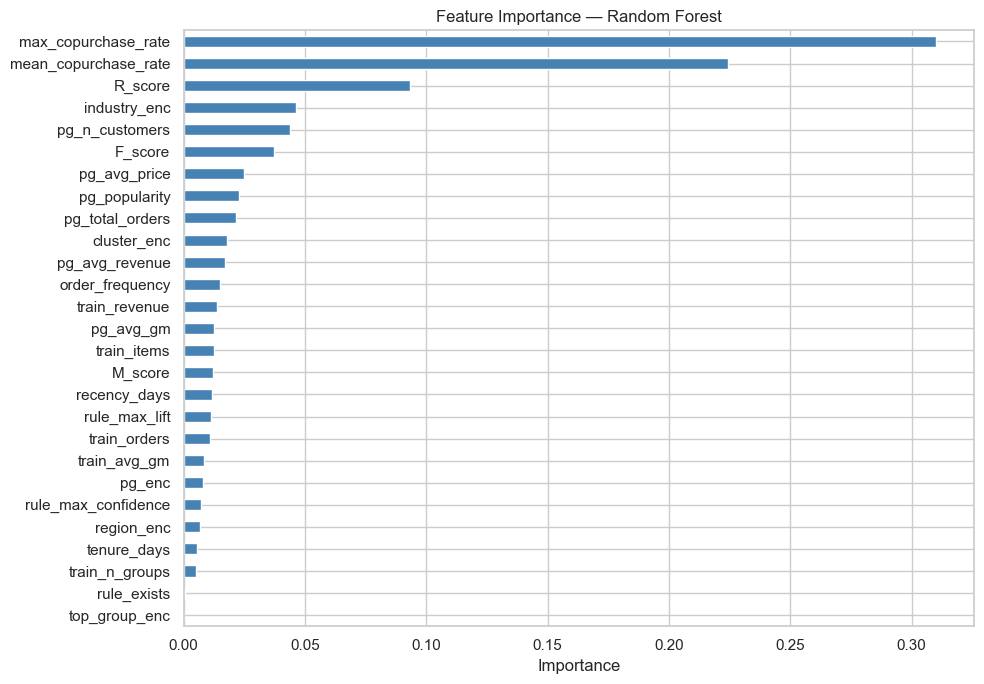

max_copurchase_rate    0.3102
mean_copurchase_rate   0.2244
R_score                0.0931
industry_enc           0.0463
pg_n_customers         0.0439
F_score                0.0371
pg_avg_price           0.0248
pg_popularity          0.0226
pg_total_orders        0.0216
cluster_enc            0.0179
pg_avg_revenue         0.0169
order_frequency        0.0150
train_revenue          0.0136
pg_avg_gm              0.0127
train_items            0.0124
M_score                0.0119
recency_days           0.0116
rule_max_lift          0.0114
train_orders           0.0109
train_avg_gm           0.0083
pg_enc                 0.0081
rule_max_confidence    0.0073
region_enc             0.0068
tenure_days            0.0056
train_n_groups         0.0051
rule_exists            0.0005
top_group_enc          0.0001
dtype: float64


In [20]:
importances = pd.Series(rf.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

importances.plot(kind='barh', color='steelblue', figsize=(10, 7))
plt.title('Feature Importance — Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False))

---
## 10. Precision@K — Kvaliteta preporuka

Za svakog kupca u test setu: jesu li Top-K preporučenih product grupa stvarno kupljene u label periodu?

In [21]:
def precision_at_k(group, k=TOP_K):
    top_k_targets = group.nlargest(k, 'probability')['target'].values
    return top_k_targets.sum() / k

# Test set predikcije — koristi best model (XGBoost ako xgb_auc >= rf_auc)
test_results = model_df.loc[idx_test, ['CustomerID', 'product_group', 'target']].copy()
test_results['probability'] = best_prob

precision_per_customer = (
    test_results.groupby('CustomerID')
    .apply(precision_at_k)
    .reset_index()
)
precision_per_customer.columns = ['CustomerID', f'precision@{TOP_K}']

avg_precision = precision_per_customer[f'precision@{TOP_K}'].mean()
print(f'Prosječni Precision@{TOP_K}: {avg_precision:.4f}')
print(f'\nInterpretacija: od top {TOP_K} preporuka po kupcu, prosječno {avg_precision*100:.1f}% je točno')
display(precision_per_customer.head(10))

Prosječni Precision@5: 0.0038

Interpretacija: od top 5 preporuka po kupcu, prosječno 0.4% je točno


,CustomerID,precision@5
0,13,0.0000
1,16,0.0000
2,22,0.0000
3,26,0.0000
4,35,0.0000
5,37,0.0000
6,40,0.0000
7,49,0.0000
8,59,0.0000
9,69,0.0000


---
## 11. Top-K preporuke za sve kupce

In [22]:
# Generiraj preporuke za sve kupce na cijelom datasetu — koristi best model (XGBoost)
model_df['xgb_probability'] = xgb.predict_proba(X)[:, 1]

# Top-K preporuke po kupcu
recommendations = (
    model_df.sort_values('xgb_probability', ascending=False)
    .groupby('CustomerID')
    .head(TOP_K)[['CustomerID', 'product_group', 'xgb_probability']]
    .sort_values(['CustomerID', 'xgb_probability'], ascending=[True, False])
    .reset_index(drop=True)
)
recommendations.columns = ['CustomerID', 'recommended_product_group', 'confidence']

print(f'Preporuke generirane za {recommendations["CustomerID"].nunique():,} kupaca')
print(f'Top-{TOP_K} preporuke po kupcu\n')
display(recommendations.head(15))

Preporuke generirane za 9,017 kupaca
Top-5 preporuke po kupcu



,CustomerID,recommended_product_group,confidence
0,13,PC021,0.0001
1,13,PC020,0.0001
2,13,PC010,0.0001
3,13,PC022,0.0001
4,13,PC001,0.0001
5,16,PC016,0.0011
6,16,PC001,0.0006
7,16,PC026,0.0004
8,16,PC019,0.0004
9,16,PC021,0.0003


---
## 12. Spremi model i preporuke

In [23]:
# Odaberi best model i spremi
best_model = xgb if xgb_auc >= rf_auc else rf
best_auc   = max(xgb_auc, rf_auc)
best_name  = 'XGBoost' if xgb_auc >= rf_auc else 'Random Forest'
print(f'Odabran model: {best_name} (AUC: {best_auc:.4f})')

joblib.dump(best_model, OUT_MODEL / 'recommender_best.pkl')
joblib.dump(rf,         OUT_MODEL / 'recommender_rf.pkl')
joblib.dump(xgb,        OUT_MODEL / 'recommender_xgb.pkl')
joblib.dump(scaler,     OUT_MODEL / 'recommender_scaler.pkl')

# Generiraj finalne preporuke s best modelom
model_df['best_probability'] = best_model.predict_proba(X)[:, 1]
recommendations = (
    model_df.sort_values('best_probability', ascending=False)
    .groupby('CustomerID')
    .head(TOP_K)[['CustomerID', 'product_group', 'best_probability']]
    .sort_values(['CustomerID', 'best_probability'], ascending=[True, False])
    .reset_index(drop=True)
)
recommendations.columns = ['CustomerID', 'recommended_product_group', 'confidence']

recommendations.to_csv(OUT_DATA / 'customer_recommendations.csv', index=False)

model_meta = {
    'best_model': best_name,
    'feature_cols': FEATURE_COLS,
    'all_product_groups': all_product_groups,
    'top_k': TOP_K,
    'train_end': str(TRAIN_END.date()),
    'label_end': str(LABEL_END.date()),
    'lr_auc': round(lr_auc, 4),
    'rf_auc': round(rf_auc, 4),
    'xgb_auc': round(xgb_auc, 4),
    'best_auc': round(best_auc, 4),
}
with open(OUT_MODEL / 'model_meta.json', 'w') as f:
    json.dump(model_meta, f, indent=2)

print('Spremljeno ✓')
print(f'  → {OUT_MODEL}/recommender_best.pkl  ({best_name})')
print(f'  → {OUT_MODEL}/recommender_rf.pkl')
print(f'  → {OUT_MODEL}/recommender_xgb.pkl')
print(f'  → {OUT_MODEL}/recommender_scaler.pkl')
print(f'  → {OUT_MODEL}/model_meta.json')
print(f'  → {OUT_DATA}/customer_recommendations.csv')

Odabran model: XGBoost (AUC: 0.9248)
Spremljeno ✓
  → ../models/recommender/recommender_best.pkl  (XGBoost)
  → ../models/recommender/recommender_rf.pkl
  → ../models/recommender/recommender_xgb.pkl
  → ../models/recommender/recommender_scaler.pkl
  → ../models/recommender/model_meta.json
  → ../data/processed/recommender/customer_recommendations.csv


---
## 13. Rolling Window Training

The original training set has only **885 real positive cross-sell events**. Rolling window training generates additional positive examples from earlier time periods — entirely before our holdout (Jul 2019 – Jun 2020) to prevent leakage.

**Three historical windows (all label periods end ≤ 2019-07-01):**
| Window | Train period | Label period |
|--------|-------------|-------------|
| 1 | Jan 2018 – Jun 2018 | Jul 2018 – Dec 2018 |
| 2 | Jan 2018 – Sep 2018 | Oct 2018 – Mar 2019 |
| 3 | Jan 2018 – Dec 2018 | Jan 2019 – Jun 2019 |

For each window: customer features are computed from that window's train data (different recency/tenure/revenue). Product features and co-purchase rates are reused from the main train period (approximation — product catalog is stable). All windows use the same 27-feature set.

The combined training set (original + 3 windows) is SMOTE-oversampled and used to retrain XGBoost. Evaluation is on the **same held-out test set** as before.

In [24]:
BASELINE_XGB_AUC = 0.8888  # XGBoost AUC before co-purchase features (original baseline)

WINDOWS = [
    (pd.Timestamp('2018-07-01'), pd.Timestamp('2019-01-01')),
    (pd.Timestamp('2018-10-01'), pd.Timestamp('2019-04-01')),
    (pd.Timestamp('2019-01-01'), pd.Timestamp('2019-07-01')),
]


def build_window_df(w_train_end, w_label_end):
    """Build a training matrix + all 27 features for one historical window."""
    w_train = df[df['Invoice Date'] < w_train_end].copy()
    w_label = df[(df['Invoice Date'] >= w_train_end) & (df['Invoice Date'] < w_label_end)].copy()

    # Customer × unseen-PG matrix
    w_train_groups = (
        w_train.groupby('CustomerID')['Product group']
        .apply(set)
        .reset_index()
    )
    w_train_groups.columns = ['CustomerID', 'train_groups']
    w_label_lookup = w_label.groupby('CustomerID')['Product group'].apply(set).to_dict()

    records = []
    for _, row in w_train_groups.iterrows():
        cid, bought = row['CustomerID'], row['train_groups']
        for pg in set(all_product_groups) - bought:
            records.append({
                'CustomerID': cid,
                'product_group': pg,
                'target': int(pg in w_label_lookup.get(cid, set()))
            })
    w_matrix = pd.DataFrame(records)

    # Customer features from this window's train period
    w_cust = w_train.groupby('CustomerID').agg(
        train_revenue=('line_revenue', 'sum'),
        train_orders=('Invoice #', 'nunique'),
        train_items=('Item Code', 'nunique'),
        train_avg_gm=('GM%', 'mean'),
        train_n_groups=('Product group', 'nunique'),
        customer_region=('Customer Region', 'first'),
        customer_industry=('Customer industry', 'first'),
        top_customer_group=('Top Customer Group', 'first'),
        first_invoice_date=('Customer First Invoice Date', 'first'),
        last_invoice_date=('Invoice Date', 'max'),
    ).reset_index()

    w_cust['recency_days']    = (w_train_end - w_cust['last_invoice_date']).dt.days
    w_cust['tenure_days']     = (w_train_end - w_cust['first_invoice_date']).dt.days
    w_cust['order_frequency'] = w_cust['train_orders'] / w_cust['tenure_days'].clip(lower=1)
    w_cust = w_cust.drop(['first_invoice_date', 'last_invoice_date'], axis=1)
    w_cust = w_cust.merge(rfm, on='CustomerID', how='left')

    le_w = LabelEncoder()
    w_cust['region_enc']    = le_w.fit_transform(w_cust['customer_region'].astype(str))
    w_cust['industry_enc']  = le_w.fit_transform(w_cust['customer_industry'].astype(str))
    w_cust['top_group_enc'] = le_w.fit_transform(w_cust['top_customer_group'].astype(str))
    w_cust['cluster_enc']   = le_w.fit_transform(w_cust['Cluster_name'].fillna('Unknown').astype(str))
    w_cust = w_cust.drop(['customer_region', 'customer_industry', 'top_customer_group', 'Cluster_name'], axis=1)

    # Merge customer + product features
    w_df = w_matrix.merge(w_cust, on='CustomerID', how='left')
    w_df = w_df.merge(product_feats, on='product_group', how='left')

    # Association rule features (same rules applied to this window's train PGs)
    w_train_map = w_train_groups.set_index('CustomerID')['train_groups'].to_dict()
    w_rule_lookup = {}
    for _, rule in rules_df.iterrows():
        ant, cons = rule['antecedents_set'], rule['consequents_set']
        lift, conf = rule['lift'], rule['confidence']
        for cid, tpgs in w_train_map.items():
            if ant.issubset(tpgs):
                for pg in cons:
                    key = (cid, pg)
                    if key not in w_rule_lookup or lift > w_rule_lookup[key][0]:
                        w_rule_lookup[key] = (lift, conf)
    if w_rule_lookup:
        w_rule_df = pd.DataFrame([
            {'CustomerID': k[0], 'product_group': k[1],
             'rule_max_lift': v[0], 'rule_max_confidence': v[1], 'rule_exists': 1}
            for k, v in w_rule_lookup.items()
        ])
        w_df = w_df.merge(w_rule_df, on=['CustomerID', 'product_group'], how='left')
    else:
        w_df['rule_exists'] = 0
        w_df['rule_max_lift'] = 0.0
        w_df['rule_max_confidence'] = 0.0
    w_df['rule_exists']         = w_df['rule_exists'].fillna(0).astype(int)
    w_df['rule_max_lift']       = w_df['rule_max_lift'].fillna(0.0)
    w_df['rule_max_confidence'] = w_df['rule_max_confidence'].fillna(0.0)

    # Co-purchase features (main train period rates reused — product catalog is stable)
    w_pg_long = w_train_groups.explode('train_groups').rename(columns={'train_groups': 'existing_pg'})
    w_cp      = w_pg_long.merge(copurchase_df, on='existing_pg')
    w_cp_agg  = (
        w_cp.groupby(['CustomerID', 'product_group'])['copurchase_rate']
        .agg(['max', 'mean'])
        .reset_index()
        .rename(columns={'max': 'max_copurchase_rate', 'mean': 'mean_copurchase_rate'})
    )
    w_df = w_df.merge(w_cp_agg, on=['CustomerID', 'product_group'], how='left')
    w_df['max_copurchase_rate']  = w_df['max_copurchase_rate'].fillna(0.0)
    w_df['mean_copurchase_rate'] = w_df['mean_copurchase_rate'].fillna(0.0)

    return w_df.fillna(w_df.median(numeric_only=True)).reset_index(drop=True)


# Build all three windows
window_dfs = []
for i, (w_train_end, w_label_end) in enumerate(WINDOWS, 1):
    print(f"Window {i}: train < {w_train_end.date()}  |  label {w_train_end.date()} – {w_label_end.date()}")
    w_df = build_window_df(w_train_end, w_label_end)
    pos = w_df['target'].sum()
    print(f"  Rows: {len(w_df):,}  |  Positives: {pos}  |  Rate: {w_df['target'].mean()*100:.3f}%")
    window_dfs.append(w_df[FEATURE_COLS + ['target']])

extra      = pd.concat(window_dfs, ignore_index=True)
X_extra    = extra[FEATURE_COLS]
y_extra    = extra['target']
print(f"\nTotal extra rows:      {len(extra):,}")
print(f"Total extra positives: {int(y_extra.sum())}  (original train positives: {int(y_train.sum())})")

Window 1: train < 2018-07-01  |  label 2018-07-01 – 2019-01-01
  Rows: 182,863  |  Positives: 664  |  Rate: 0.363%
Window 2: train < 2018-10-01  |  label 2018-10-01 – 2019-04-01
  Rows: 208,094  |  Positives: 651  |  Rate: 0.313%
Window 3: train < 2019-01-01  |  label 2019-01-01 – 2019-07-01
  Rows: 225,900  |  Positives: 643  |  Rate: 0.285%

Total extra rows:      616,857
Total extra positives: 1958  (original train positives: 708)


In [25]:
# Combine original training data + all rolling window data
X_train_rw = pd.concat([X_train, X_extra], ignore_index=True)
y_train_rw = pd.concat([y_train, y_extra], ignore_index=True)

print(f"Combined train rows:      {len(X_train_rw):,}")
print(f"Combined positives:       {int(y_train_rw.sum())}  ({y_train_rw.mean()*100:.3f}%)")

smote_rw = SMOTE(sampling_strategy=0.1, random_state=42, k_neighbors=5)
X_rw_sm, y_rw_sm = smote_rw.fit_resample(X_train_rw, y_train_rw)
print(f"After SMOTE:              {len(X_rw_sm):,} rows")

# Retrain XGBoost on expanded data — same hyperparameters, same test set
xgb_rw = XGBClassifier(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, verbosity=0
)
xgb_rw.fit(X_rw_sm, y_rw_sm)

xgb_rw_prob = xgb_rw.predict_proba(X_test)[:, 1]
xgb_rw_auc  = roc_auc_score(y_test, xgb_rw_prob)

print(f"\n{'═'*52}")
print(f"  Model Progression")
print(f"{'─'*52}")
print(f"  Baseline XGBoost (25 features):          {BASELINE_XGB_AUC:.4f}")
print(f"  + Co-purchase features (27 features):    {xgb_auc:.4f}  Δ{xgb_auc - BASELINE_XGB_AUC:+.4f}")
print(f"  + Rolling window (27 feat + 3 windows):  {xgb_rw_auc:.4f}  Δ{xgb_rw_auc - BASELINE_XGB_AUC:+.4f}")
print(f"{'═'*52}")

# Save the better model
if xgb_rw_auc > xgb_auc:
    print(f"\nRolling window improved AUC by {xgb_rw_auc - xgb_auc:+.4f} — saving as best model")
    joblib.dump(xgb_rw, OUT_MODEL / 'recommender_best.pkl')

    model_df['best_probability'] = xgb_rw.predict_proba(X)[:, 1]
    recs_rw = (
        model_df.sort_values('best_probability', ascending=False)
        .groupby('CustomerID')
        .head(TOP_K)[['CustomerID', 'product_group', 'best_probability']]
        .sort_values(['CustomerID', 'best_probability'], ascending=[True, False])
        .reset_index(drop=True)
    )
    recs_rw.columns = ['CustomerID', 'recommended_product_group', 'confidence']
    recs_rw.to_csv(OUT_DATA / 'customer_recommendations.csv', index=False)

    with open(OUT_MODEL / 'model_meta.json') as f:
        meta = json.load(f)
    meta['best_model']  = 'XGBoost + Rolling Window'
    meta['best_auc']    = round(xgb_rw_auc, 4)
    meta['xgb_rw_auc'] = round(xgb_rw_auc, 4)
    meta['n_windows']   = len(WINDOWS)
    with open(OUT_MODEL / 'model_meta.json', 'w') as f:
        json.dump(meta, f, indent=2)

    print(f"Saved: {OUT_MODEL}/recommender_best.pkl")
    print(f"Saved: {OUT_DATA}/customer_recommendations.csv")
    print(f"Saved: {OUT_MODEL}/model_meta.json")
else:
    print(f"\nRolling window did not improve AUC — current best model ({xgb_auc:.4f}) kept")

Combined train rows:      822,543
Combined positives:       2666  (0.324%)
After SMOTE:              901,864 rows

════════════════════════════════════════════════════
  Model Progression
────────────────────────────────────────────────────
  Baseline XGBoost (25 features):          0.8888
  + Co-purchase features (27 features):    0.9248  Δ+0.0360
  + Rolling window (27 feat + 3 windows):  0.9164  Δ+0.0276
════════════════════════════════════════════════════

Rolling window did not improve AUC — current best model (0.9248) kept
